# 10 - Naive Bayes

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Train and evaluate a Gaussian Naive Bayes model on the processed PhiUSIIL data, compare different feature sets, test the URL-only version on the external dataset, choose a better cut-off, and find out which features the model relies on.

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`, `results/feature_importance/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.naive_bayes import GaussianNB

sys.path.append(str(Path("..").resolve()))
from src.data import PROCESSED_DIR, get_feature_sets, load_feature_groups, load_train_test, sample_rows
from src.evaluation import (
    RANDOM_STATE,
    cross_validate_model,
    evaluate_model,
    evaluate_predictions,
    get_scores,
    make_cv,
    make_scaled_pipeline,
    plot_confusion_matrix,
    save_results,
    to_file_name,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 187,363 rows | 69 features
Test set:     46,841 rows | 69 features


## Model Settings

Gaussian Naive Bayes uses Bayes' theorem. For each URL, it asks: "Given these feature values, is phishing or legitimate more likely?" To keep the maths simple, it makes two assumptions:

1. **Every feature follows a bell curve (normal distribution)** inside each class.
2. **The features are independent** of each other once we know the class. This is the "naive" part.

Our EDA found that 26 of the 31 continuous features are highly skewed, so we use `make_scaled_pipeline`. It applies a log transform (`log1p`), which makes skewed features closer to a bell curve, and then scales them. Both steps are fitted only on the training data, inside the pipeline.

Naive Bayes has only one setting to tune: `var_smoothing`. It adds a small amount to the variance of every feature, so that a feature with almost no spread cannot dominate the prediction. We try values from 10⁻¹² to 10⁻².

Naive Bayes trains in seconds, so we use the full training set for tuning (`TUNING_SAMPLE_SIZE = None`).

In [3]:
MODEL_NAME = "Naive Bayes"
model = make_scaled_pipeline(GaussianNB())

param_grid = {
    "gaussiannb__var_smoothing": np.logspace(-12, -2, 6),
}

TUNING_SAMPLE_SIZE = None

## 1. Hyperparameter Tuning

We try each value in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(X_train, y_train, TUNING_SAMPLE_SIZE)

search = GridSearchCV(model, param_grid, scoring="f1", cv=make_cv(3), n_jobs=-1)
search.fit(X_tune, y_tune)
best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'gaussiannb__var_smoothing': np.float64(1e-12)}
Best cross-validation F1: 0.9997


In [5]:
tuning_table = pd.DataFrame({
    "var_smoothing": [f"{v:.0e}" for v in search.cv_results_["param_gaussiannb__var_smoothing"]],
    "Mean F1": search.cv_results_["mean_test_score"],
    "Std": search.cv_results_["std_test_score"],
})
tuning_table.round(4)

,var_smoothing,Mean F1,Std
0,1e-12,0.9997,0.0001
1,1e-10,0.9996,0.0002
2,1e-08,0.9995,0.0002
3,1e-06,0.9994,0.0001
4,1e-04,0.9992,0.0001
5,1e-02,0.9987,0.0002


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [6]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,0.9997,0.0001
Precision,0.9995,0.0003
Recall,0.9999,0.0001
F1,0.9997,0.0002
ROC-AUC,0.9999,0.0001


## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [7]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 0.3 seconds


,Test Score
Accuracy,0.9997
Precision,0.9994
Recall,0.9999
F1,0.9996
ROC-AUC,0.9998


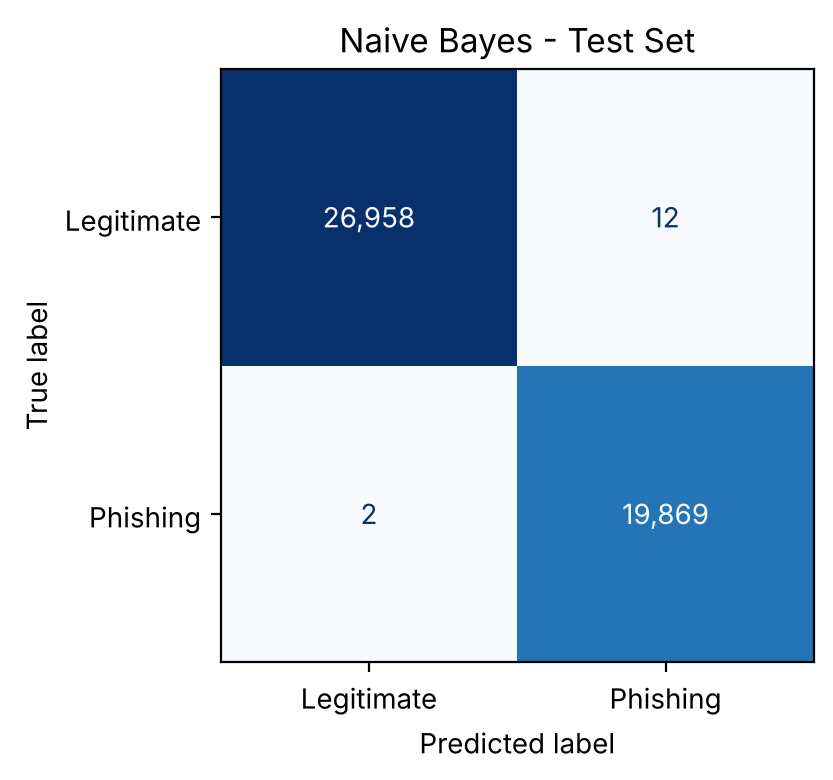

In [8]:
test_pred = final_model.predict(X_test)
plot_confusion_matrix(y_test, test_pred, f"{MODEL_NAME} - Test Set")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [9]:
feature_results = {"All features": test_results}

for set_name in ["Original features only", "Without URLSimilarityIndex"]:
    features = feature_sets[set_name]
    set_model = clone(best_model).fit(X_train[features], y_train)
    feature_results[set_name] = evaluate_model(set_model, X_test[features], y_test)

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
All features,0.9997,0.9994,0.9999,0.9996,0.9998
Original features only,0.9995,0.9989,0.9999,0.9994,0.9997
Without URLSimilarityIndex,0.9957,0.9993,0.9904,0.9949,0.9998


## 5. Choosing the Cut-off

By default, a URL is called phishing when the model gives it a probability of 0.5 or more. But the two mistakes do not cost the same: **a missed phishing URL can steal a user's password, while a false alarm only blocks a safe page**. So we choose the cut-off based on the cost of errors.

Our rule: **find at least 95% of phishing URLs (recall ≥ 0.95), and among the cut-offs that do this, pick the one with the fewest false alarms (highest precision).**

To choose the cut-off without touching the test set, we use *out-of-fold* predictions: with 5-fold cross-validation, every training URL gets a probability from a model that did not see it during training. We then apply the chosen cut-off to the test set once.

This step is especially useful for Naive Bayes, because its independence assumption pushes most probabilities very close to 0 or 1, so 0.5 is not always a good place to cut.

In [10]:
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=make_cv(5), method="predict_proba", n_jobs=-1)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)

TARGET_RECALL = 0.95
meets_target = recall[:-1] >= TARGET_RECALL
best_threshold = thresholds[meets_target][np.argmax(precision[:-1][meets_target])]
print(f"Chosen cut-off: {best_threshold:.4f}")

Chosen cut-off: 1.0000


In [11]:
test_proba = final_model.predict_proba(X_test)[:, 1]
tuned_pred = (test_proba >= best_threshold).astype(int)
tuned_results = evaluate_predictions(y_test, tuned_pred, test_proba)

pd.DataFrame({
    "Cut-off 0.5": test_results,
    f"Cut-off {best_threshold:.4f}": tuned_results,
}).round(4)

,Cut-off 0.5,Cut-off 1.0000
Accuracy,0.9997,0.9998
Precision,0.9994,0.9995
Recall,0.9999,0.9999
F1,0.9996,0.9997
ROC-AUC,0.9998,0.9998


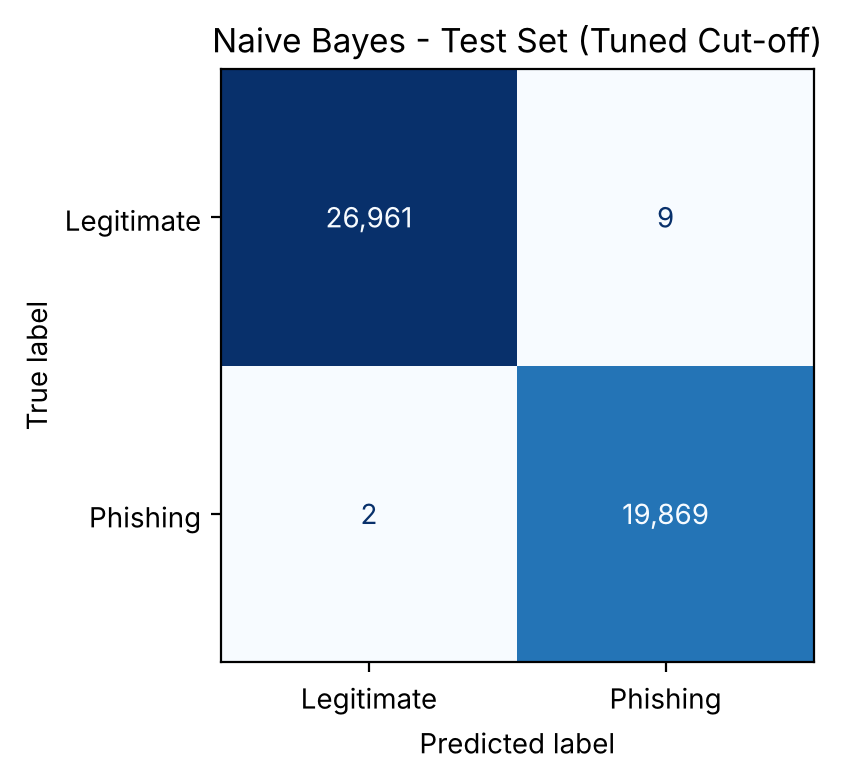

In [12]:
plot_confusion_matrix(y_test, tuned_pred, f"{MODEL_NAME} - Test Set (Tuned Cut-off)")

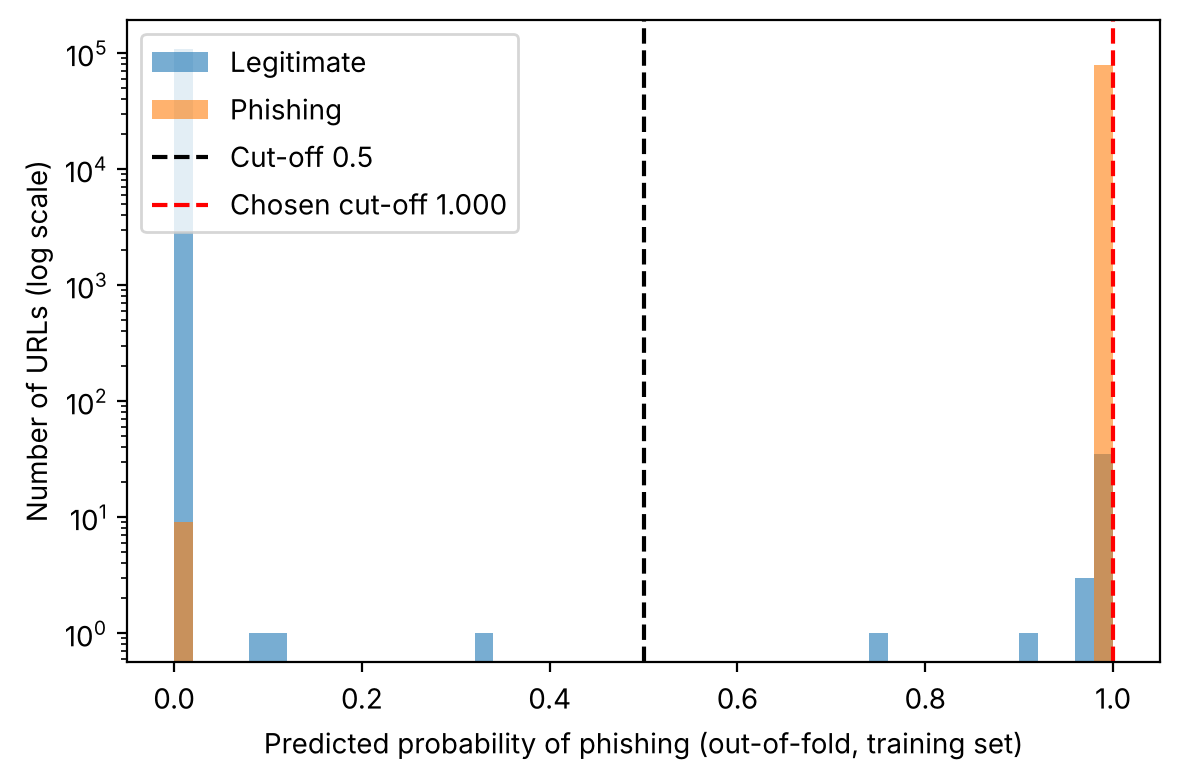

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(oof_proba[y_train == 0], bins=50, alpha=0.6, label="Legitimate", log=True)
ax.hist(oof_proba[y_train == 1], bins=50, alpha=0.6, label="Phishing", log=True)
ax.axvline(0.5, color="black", linestyle="--", label="Cut-off 0.5")
ax.axvline(best_threshold, color="red", linestyle="--", label=f"Chosen cut-off {best_threshold:.3f}")
ax.set_xlabel("Predicted probability of phishing (out-of-fold, training set)")
ax.set_ylabel("Number of URLs (log scale)")
ax.legend()
fig.tight_layout()
plt.show()

**What this shows:** Naive Bayes is extremely over-confident. Almost every phishing URL in the training set (99.99%) gets a probability of exactly 1.0, so the histogram has almost nothing in the middle. Because of this, the rule picks a cut-off of 1.0, which means "only call a URL phishing when the model is completely sure". On the test set this removes 3 false alarms (12 → 9) and misses no extra phishing URLs (still 2). That is 3 URLs out of 46,841, which is too small to be a meaningful difference, and a cut-off of exactly 1.0 is fragile. So we keep **0.5 as the main result** for this model and report the tuned cut-off only as an extra.

## 6. Prediction Speed

A phishing detector must be fast, because it checks every link a user opens. We measure how long the model takes to classify all test URLs.

In [14]:
start = time.perf_counter()
final_model.predict(X_test)
predict_time = time.perf_counter() - start

print(f"Training time:   {train_time:.2f} seconds")
print(f"Prediction time: {predict_time:.3f} seconds for {len(X_test):,} URLs "
      f"({predict_time / len(X_test) * 1e6:.1f} microseconds per URL)")

Training time:   0.32 seconds
Prediction time: 0.036 seconds for 46,841 URLs (0.8 microseconds per URL)


## 7. Which Features Does the Model Rely On?

Naive Bayes does not give feature importances directly, so we use **permutation importance**: we shuffle one feature at a time on the test set and see how much ROC-AUC drops. If the score drops a lot, the model was relying on that feature. We use a sample of 10,000 test URLs and repeat each shuffle 3 times.

Many of our features are correlated, so shuffling one feature can look harmless because a "twin" feature still carries the same information. To handle this, we also shuffle **whole groups** of features at once.

In [15]:
get_score = get_scores

def permutation_auc_drop(model, X, y, groups, repeats=3):
    """Shuffle each group of columns together and measure how much ROC-AUC drops."""
    rng = np.random.default_rng(RANDOM_STATE)
    base = roc_auc_score(y, get_score(model, X))
    rows = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(repeats):
            X_shuffled = X.copy()
            X_shuffled[cols] = X_shuffled[cols].values[rng.permutation(len(X_shuffled))]
            drops.append(base - roc_auc_score(y, get_score(model, X_shuffled)))
        rows[name] = {"AUC drop": np.mean(drops), "Std": np.std(drops)}
    return pd.DataFrame(rows).T.sort_values("AUC drop", ascending=False)

X_imp, y_imp = sample_rows(X_test, y_test, 10000)

start = time.perf_counter()
single_importance = permutation_auc_drop(final_model, X_imp, y_imp, {col: [col] for col in X_imp.columns})
print(f"Done in {time.perf_counter() - start:.0f} seconds")
single_importance.head(15).round(4)

Done in 3 seconds


,AUC drop,Std
URLSimilarityIndex,0.2121,0.0007
NoOfSlashesInURL,0.1248,0.0015
PathLength,0.1243,0.0018
IsHTTPS,0.1084,0.0019
PathDepth,0.0563,0.0003
QueryLength,0.0126,0.0006
NoOfQMarkInURL,0.0124,0.0002
HasTitle,0.0121,0.0009
NoOfEqualsInURL,0.0109,0.0004
HasAtSymbol,0.0026,0.0001


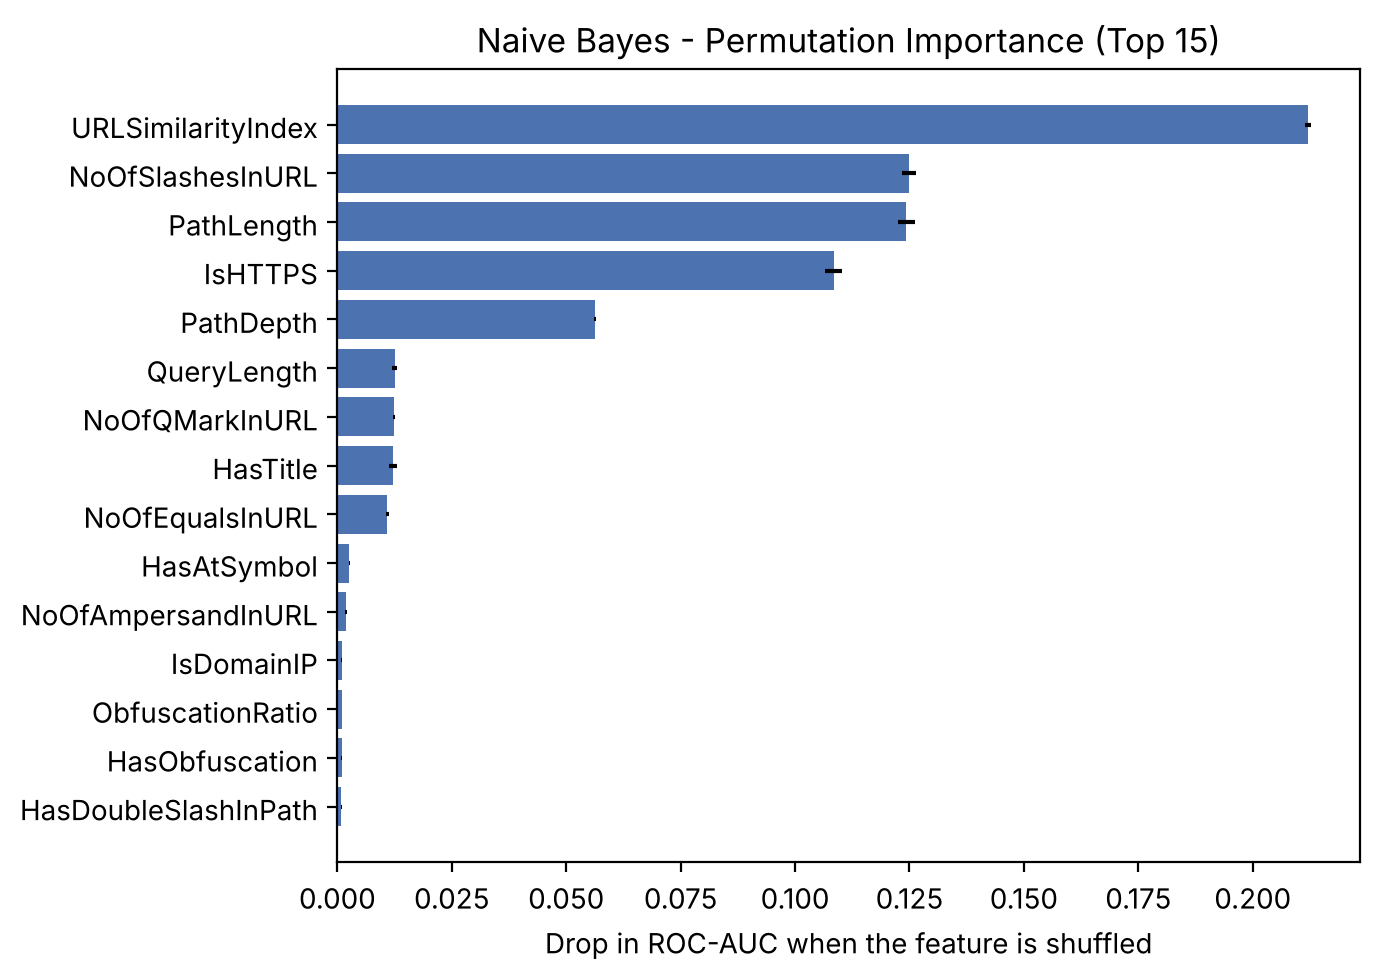

In [16]:
save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)

top = single_importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top["AUC drop"], xerr=top["Std"], color="#4C72B0")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.set_title(f"{MODEL_NAME} - Permutation Importance (Top 15)")
fig.tight_layout()
fig.savefig(save_dir / f"{to_file_name(MODEL_NAME)}.png", dpi=300)
plt.show()

In [17]:
groups = load_feature_groups()
group_importance = permutation_auc_drop(final_model, X_imp, y_imp, {
    "URLSimilarityIndex": ["URLSimilarityIndex"],
    "Other original features (47)": [col for col in groups["original"] if col != "URLSimilarityIndex"],
    "Engineered features (21)": groups["engineered"],
})
group_importance.round(4)

,AUC drop,Std
URLSimilarityIndex,0.2135,0.0024
Other original features (47),0.1477,0.0021
Engineered features (21),0.1256,0.0011


## 8. Where Does the Model Go Wrong?

A score tells us how often the model is wrong, but not why. Here we look at the URLs the model got wrong at the default cut-off (0.5).

In [18]:
test_urls = pd.read_csv(PROCESSED_DIR / "test_urls.csv")["URL"].values
errors = pd.DataFrame({"URL": test_urls, "Actual": y_test.values, "Predicted": test_pred})

missed = errors[(errors["Actual"] == 1) & (errors["Predicted"] == 0)]
false_alarms = errors[(errors["Actual"] == 0) & (errors["Predicted"] == 1)]
print(f"Missed phishing URLs (false negatives): {len(missed):,}")
print(f"False alarms (false positives):         {len(false_alarms):,}")

Missed phishing URLs (false negatives): 2
False alarms (false positives):         12


In [19]:
print("Examples of missed phishing URLs:")
display(missed.sample(min(10, len(missed)), random_state=RANDOM_STATE)[["URL"]])
print("Examples of false alarms:")
display(false_alarms.sample(min(10, len(false_alarms)), random_state=RANDOM_STATE)[["URL"]])

Examples of missed phishing URLs:


,URL
4218,https://midgleyspublichouse.com
3381,https://www.wsend.co


Examples of false alarms:


,URL
34903,https://www.wiskuu.nl
31027,https://www.lewiscarrollcentre.org.uk
45,https://www.counterpointpress.com
24910,https://www.vocaleapp.com
10392,https://www.oppaga.fl.gov
4383,https://www.bauermedia.co.uk
1378,https://www.calafco.org
36645,https://www.britisharmedforces.org
8614,https://www.1920-30.com
16291,https://www.guizot.com


In [20]:
def url_shape(urls):
    urls = pd.Series(urls)
    return pd.Series({
        "Avg URL length": urls.str.len().mean(),
        "Has a path (%)": urls.str.replace(r"^https?://", "", regex=True).str.contains("/.", regex=True).mean() * 100,
        "Uses HTTPS (%)": urls.str.startswith("https").mean() * 100,
    })

pd.DataFrame({
    "All phishing": url_shape(errors.loc[errors["Actual"] == 1, "URL"]),
    "Missed phishing": url_shape(missed["URL"]),
    "All legitimate": url_shape(errors.loc[errors["Actual"] == 0, "URL"]),
    "False alarms": url_shape(false_alarms["URL"]),
}).round(1)

,All phishing,Missed phishing,All legitimate,False alarms
Avg URL length,46.1,25.5,27.2,27.2
Has a path (%),28.2,0.0,0.0,0.0
Uses HTTPS (%),48.7,100.0,100.0,100.0


## 9. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [21]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time, "Predict Time (s)": predict_time},
    {"Experiment": f"Test set - Tuned cut-off ({best_threshold:.4f})", **tuned_results},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
]

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s),Predict Time (s)
0,Naive Bayes,Cross-validation,0.9997,0.9995,0.9999,0.9997,0.9999,NaN,NaN
1,Naive Bayes,Test set - All features,0.9997,0.9994,0.9999,0.9996,0.9998,0.3206,0.0365
2,Naive Bayes,Test set - Tuned cut-off (1.0000),0.9998,0.9995,0.9999,0.9997,0.9998,NaN,NaN
3,Naive Bayes,Test set - Original features only,0.9995,0.9989,0.9999,0.9994,0.9997,NaN,NaN
4,Naive Bayes,Test set - Without URLSimilarityIndex,0.9957,0.9993,0.9904,0.9949,0.9998,NaN,NaN


## 10. Findings

**1. Very high scores on the PhiUSIIL test set.** Naive Bayes reaches 99.97% accuracy, an F1-score of 0.9996 and a ROC-AUC of 0.9998. It missed only **2 of 19,871** phishing URLs and wrongly flagged **12 of 26,970** legitimate URLs. The cross-validation F1 (0.9997 ± 0.0002) is almost the same as the test F1, so the cross-validation estimate was honest and the model is not overfitting.

**2. Tuning barely mattered.** All `var_smoothing` values gave an F1 between 0.9987 and 0.9997. The smallest value (10⁻¹²) was best, but the differences are tiny.

**3. Very fast.** Training took about 0.3 seconds and predicting 46,841 URLs about 0.04 seconds (about 1 microsecond per URL). This makes Naive Bayes a good choice for real-time checking. (Times depend on the computer used.)

**4. The new features helped only a little.** With original features only, F1 was 0.9994. With our engineered features, it was 0.9996. The gap is too small to claim a meaningful improvement.

**5. `URLSimilarityIndex` matters most, but the model still works without it.** Without this feature, recall drops from 0.9999 to 0.990 (188 more phishing URLs missed), while precision stays at 0.999. ROC-AUC is still 0.9998, so the model still *ranks* URLs well, but the 0.5 cut-off no longer fits as well. Permutation importance agrees: shuffling `URLSimilarityIndex` lowers ROC-AUC by 0.21, followed by `NoOfSlashesInURL` (0.12), `PathLength` (0.12), `IsHTTPS` (0.11) and `PathDepth` (0.06). These show which features the model *relies on*, not what *causes* a URL to be phishing.

**6. The mistakes reveal how the dataset was built.** In the PhiUSIIL test set, **every legitimate URL is a plain HTTPS home page** (0% have a path, 100% use HTTPS), while 28.2% of phishing URLs have a path and only 48.7% use HTTPS. The 2 missed phishing URLs and all 12 false alarms are plain HTTPS home pages, so the model only fails where a phishing URL looks exactly like a typical legitimate URL in this dataset. This also means the near-perfect scores partly reflect how PhiUSIIL was collected, which we test in Experiment 2.

**7. Choosing a cut-off did not change the result.** Naive Bayes gives almost every phishing URL a probability of exactly 1.0. The tuned cut-off (1.0) removed 3 false alarms, which is not a meaningful difference, so we report the 0.5 cut-off as the main result.

**Limitation:** Naive Bayes assumes that features are independent, but many of our features are correlated (for example, `NoOfSlashesInURL`, `PathLength` and `PathDepth` all describe the URL path). This is the reason for its over-confident probabilities. It still works well here because a few features separate the classes so clearly.

**Next step:** Train on more varied legitimate URLs (inner pages and non-HTTPS sites), so the model does not learn "has a path" or "no HTTPS" as a sign of phishing.